In [ ]:
%%capture
import os, re
if "COLAB_" not in "".join(os.environ.keys()):
    !pip install "unsloth==2026.1.3"
else:
    # Do this only in Colab notebooks! Otherwise use pip install unsloth
    import torch; v = re.match(r"[0-9]{1,}\.[0-9]{1,}", str(torch.__version__)).group(0)
    xformers = "xformers==" + ("0.0.33.post1" if v=="2.9" else "0.0.32.post2" if v=="2.8" else "0.0.29.post3")
    !pip install --no-deps bitsandbytes accelerate {xformers} peft trl triton cut_cross_entropy unsloth_zoo
    !pip install sentencepiece protobuf "datasets==4.3.0" "huggingface_hub>=0.34.0" hf_transfer
    !pip install --no-deps "unsloth==2026.1.3"
!pip install transformers==4.56.2
!pip install --no-deps trl==0.22.2
from unsloth import FastVisionModel # FastLanguageModel for LLMs
import torch

model, processor = FastVisionModel.from_pretrained(
    "unsloth/gemma-3-4b-it",
    load_in_4bit = True, # Use 4bit to reduce memory use. False for 16bit LoRA.
    use_gradient_checkpointing = "unsloth", # True or "unsloth" for long context
)
from unsloth import get_chat_template

processor = get_chat_template(
    processor,
    "gemma-3"
)
from datasets import load_dataset
test_ds = load_dataset(
    "123ccls/POLCOVID_task1_70_10_20",  # 🔁 CHANGE THIS
    split="test"
)

In [ ]:
from pathlib import Path
import pandas as pd
import re

TASK_ID = "Task1_nshot"
RESULTS_PROJECT_ROOT = Path(
    r"C:\Users\Henryayay\OneDrive - The Hong Kong Polytechnic University\Desktop\AI xray classification project\Results"
)
LOCAL_RESULTS_ROOT = RESULTS_PROJECT_ROOT / "ICL" / "Task1"

def _slug(text):
    text = str(text).strip().replace(" ", "-")
    return re.sub(r"[^A-Za-z0-9._-]+", "_", text)

def record_and_save_run(y_true, y_pred, setup, model, accuracy_pct, task_id=TASK_ID, trigger_download=True, name_to_id=None):
    """Save predictions under Results/<method>/<task>/ with task, setup, model, and accuracy in the filename."""
    if name_to_id is None:
        name_to_id = NAME_TO_ID if 'NAME_TO_ID' in globals() else {"Normal": 0, "Pneumonia": 1}
    y_true = list(y_true)
    y_pred = list(y_pred)
    df = pd.DataFrame({
        "Index": range(len(y_true)),
        "True_Label_ID": [name_to_id.get(str(v).strip(), -1) for v in y_true],
        "Predicted_Label_ID": [name_to_id.get(str(v).strip(), -1) for v in y_pred],
        "True_Label_Name": y_true,
        "Predicted_Label_Name": y_pred,
    })

    acc_label = f"{float(accuracy_pct):.2f}pct"
    filename = f"{_slug(task_id)}_{_slug(setup)}_{_slug(model)}_acc{acc_label}.csv"

    dest_dir = None
    for candidate in (LOCAL_RESULTS_ROOT, Path.cwd() / "Results" / "ICL" / "Task1"):
        try:
            candidate.mkdir(parents=True, exist_ok=True)
            probe = candidate / ".write_test"
            probe.write_text("ok", encoding="utf-8")
            probe.unlink()
            dest_dir = candidate
            break
        except Exception:
            continue
    if dest_dir is None:
        dest_dir = Path.cwd() / "Results" / "ICL" / "Task1"
        dest_dir.mkdir(parents=True, exist_ok=True)

    dest_path = dest_dir / filename
    df.to_csv(dest_path, index=False)
    print(f"Saved predictions to: {dest_path}")

    errors = df[df["Predicted_Label_ID"] == -1]
    if len(errors) > 0:
        print(f"WARNING: {len(errors)} predictions could not be mapped to IDs!")
        print(errors["Predicted_Label_Name"].unique())
    else:
        print("Verification Passed: All predictions mapped correctly.")

    saved_on_pc = str(LOCAL_RESULTS_ROOT) in str(dest_path)
    if trigger_download and not saved_on_pc:
        cwd_copy = Path.cwd() / filename
        if cwd_copy.resolve() != dest_path.resolve():
            df.to_csv(cwd_copy, index=False)
        try:
            from google.colab import files
            print(f"Starting download for {filename}")
            print(f"If the browser save dialog appears, choose:\n{LOCAL_RESULTS_ROOT}")
            files.download(str(cwd_copy if cwd_copy.exists() else dest_path))
        except Exception as exc:
            print(f"Could not auto-download to your PC ({exc}). Copy this file to:\n{LOCAL_RESULTS_ROOT}")
    return dest_path


# **2 shots**

100%|██████████| 456/456 [20:29<00:00,  2.70s/it]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ 2-Shot Metrics
              precision    recall  f1-score   support

      Normal       0.74      0.14      0.24       228
   Pneumonia       0.53      0.95      0.68       228

    accuracy                           0.55       456
   macro avg       0.63      0.55      0.46       456
weighted avg       0.63      0.55      0.46       456



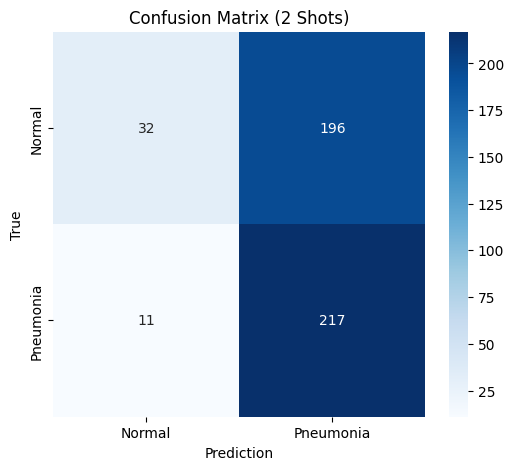

In [ ]:
import random
from datasets import load_dataset
from tqdm import tqdm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import pandas as pd
from google.colab import files

train_ds = load_dataset("123ccls/POLCOVID_task1_70_10_20", split="train")

def get_few_shot_examples(dataset, total_shots=2):
    shots_per_class = total_shots // 2
    normal_indices = [i for i, x in enumerate(dataset) if x['label'] == 0]
    pneumonia_indices = [i for i, x in enumerate(dataset) if x['label'] == 1]
    selected_normal = random.sample(normal_indices, shots_per_class)
    selected_pneumonia = random.sample(pneumonia_indices, shots_per_class)
    examples = []
    all_indices = [(idx, "Normal") for idx in selected_normal] + [(idx, "Pneumonia") for idx in selected_pneumonia]
    random.shuffle(all_indices)
    for idx, label in all_indices:
        examples.append({"image": dataset[idx]["image"], "label": label})
    return examples

N_SHOTS = 2
LABEL_MAP = {0: "Normal", 1: "Pneumonia"}
NAME_TO_ID = {"Normal": 0, "Pneumonia": 1}
icl_examples = get_few_shot_examples(train_ds, total_shots=N_SHOTS)
y_true, y_pred = [], []

for sample in tqdm(test_ds):
    y_true.append(LABEL_MAP[sample["label"]])
    content, images = [], []
    for i, ex in enumerate(icl_examples):
        content.append({"type": "text", "text": f"--- EXAMPLE {i+1} ---\nDiagnosis: {ex['label']}\nImage:"})
        content.append({"type": "image"})
        images.append(ex["image"])
    content.append({"type": "text", "text": "\n--- TASK ---\nYou are an expert radiologist. Analyze this chest X-ray and classify it as 'Normal' or 'Pneumonia'. Output ONLY the single word answer.\nFinal Image:"})
    content.append({"type": "image"})
    images.append(sample["image"])
    messages = [{"role": "user", "content": content}]
    input_text = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=input_text, images=images, return_tensors="pt", padding=True).to("cuda")
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=15, temperature=0.01, use_cache=True)
    response = processor.batch_decode(output[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()
    pred_label = "Pneumonia" if "Pneumonia" in response else "Normal" if "Normal" in response else "Error"
    y_pred.append(pred_label)

acc = accuracy_score(y_true, y_pred) * 100
print(f"Accuracy for {N_SHOTS}-shot: {acc:.2f}%")
record_and_save_run(
    y_true,
    y_pred,
    setup=f"{N_SHOTS}shot",
    model="gemma-3-4b-it",
    accuracy_pct=acc,
)



✅ Results for 2-Shot Experiment
Accuracy: 54.61%

Full Report:
              precision    recall  f1-score   support

      Normal       0.74      0.14      0.24       228
   Pneumonia       0.53      0.95      0.68       228

    accuracy                           0.55       456
   macro avg       0.63      0.55      0.46       456
weighted avg       0.63      0.55      0.46       456



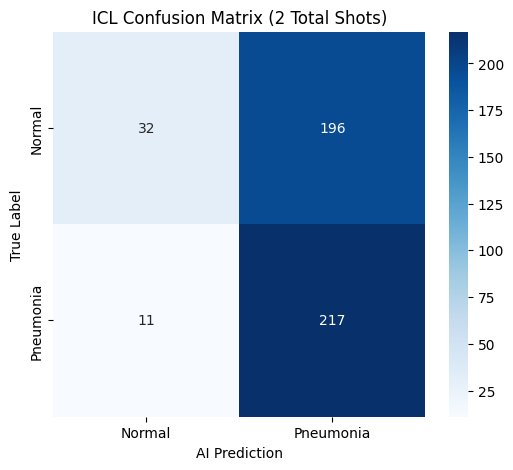

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Note: This uses the most recent evaluation results stored in y_true/y_pred
if 'y_true' in globals() and 'y_pred' in globals():
    acc = accuracy_score(y_true, y_pred)
    print(f"\n✅ Results for {N_SHOTS}-Shot Experiment")
    print(f"Accuracy: {acc*100:.2f}%")
    print("\nFull Report:")
    print(classification_report(y_true, y_pred, labels=["Normal", "Pneumonia"]))

    plt.figure(figsize=(6,5))
    cm = confusion_matrix(y_true, y_pred, labels=["Normal", "Pneumonia"])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=["Normal", "Pneumonia"],
                yticklabels=["Normal", "Pneumonia"])
    plt.title(f'ICL Confusion Matrix ({N_SHOTS} Total Shots)')
    plt.xlabel('AI Prediction')
    plt.ylabel('True Label')
    plt.show()
else:
    print("Variable y_true/y_pred not found. Please ensure you have run the inference cell for this shot-count.")

# **4 shot**

100%|██████████| 456/456 [32:18<00:00,  4.25s/it]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ 4-Shot Metrics
              precision    recall  f1-score   support

      Normal       0.73      0.12      0.20       228
   Pneumonia       0.52      0.96      0.67       228

    accuracy                           0.54       456
   macro avg       0.63      0.54      0.44       456
weighted avg       0.63      0.54      0.44       456



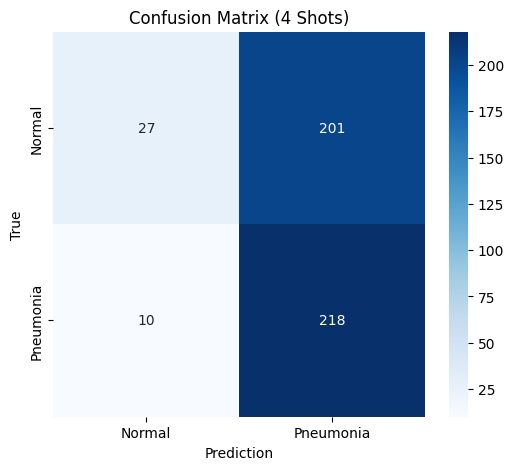

In [ ]:
N_SHOTS = 4
icl_examples = get_few_shot_examples(train_ds, total_shots=N_SHOTS)
y_true, y_pred = [], []

for sample in tqdm(test_ds):
    y_true.append(LABEL_MAP[sample["label"]])
    content, images = [], []
    for i, ex in enumerate(icl_examples):
        content.append({"type": "text", "text": f"--- EXAMPLE {i+1} ---\nDiagnosis: {ex['label']}\nImage:"})
        content.append({"type": "image"})
        images.append(ex["image"])
    content.append({"type": "text", "text": "\n--- TASK ---\nYou are an expert radiologist. Analyze this chest X-ray and classify it as 'Normal' or 'Pneumonia'. Output ONLY the single word answer.\nFinal Image:"})
    content.append({"type": "image"})
    images.append(sample["image"])
    messages = [{"role": "user", "content": content}]
    input_text = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=input_text, images=images, return_tensors="pt", padding=True).to("cuda")
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=15, temperature=0.01, use_cache=True)
    response = processor.batch_decode(output[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()
    pred_label = "Pneumonia" if "Pneumonia" in response else "Normal" if "Normal" in response else "Error"
    y_pred.append(pred_label)

acc = accuracy_score(y_true, y_pred) * 100
print(f"Accuracy for {N_SHOTS}-shot: {acc:.2f}%")

acc = accuracy_score(y_true, y_pred) * 100
print(f"Accuracy for {N_SHOTS}-shot: {acc:.2f}%")
record_and_save_run(
    y_true,
    y_pred,
    setup=f"{N_SHOTS}shot",
    model="gemma-3-4b-it",
    accuracy_pct=acc,
)


# **6 shot**

100%|██████████| 456/456 [44:04<00:00,  5.80s/it]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ 6-Shot Metrics
              precision    recall  f1-score   support

      Normal       0.67      0.39      0.50       228
   Pneumonia       0.57      0.81      0.67       228

    accuracy                           0.60       456
   macro avg       0.62      0.60      0.58       456
weighted avg       0.62      0.60      0.58       456



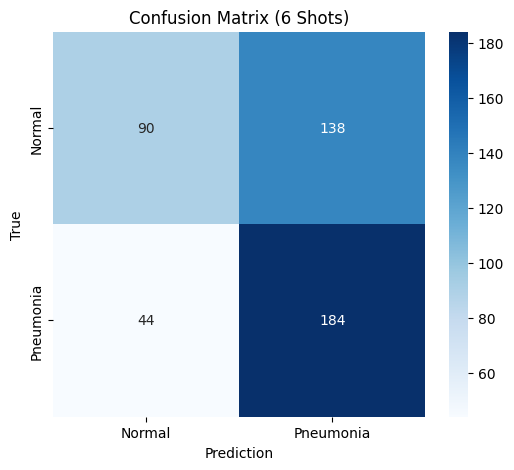

In [ ]:
N_SHOTS = 6
icl_examples = get_few_shot_examples(train_ds, total_shots=N_SHOTS)
y_true, y_pred = [], []

for sample in tqdm(test_ds):
    y_true.append(LABEL_MAP[sample["label"]])
    content, images = [], []
    for i, ex in enumerate(icl_examples):
        content.append({"type": "text", "text": f"--- EXAMPLE {i+1} ---\nDiagnosis: {ex['label']}\nImage:"})
        content.append({"type": "image"})
        images.append(ex["image"])
    content.append({"type": "text", "text": "\n--- TASK ---\nYou are an expert radiologist. Analyze this chest X-ray and classify it as 'Normal' or 'Pneumonia'. Output ONLY the single word answer.\nFinal Image:"})
    content.append({"type": "image"})
    images.append(sample["image"])
    messages = [{"role": "user", "content": content}]
    input_text = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=input_text, images=images, return_tensors="pt", padding=True).to("cuda")
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=15, temperature=0.01, use_cache=True)
    response = processor.batch_decode(output[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()
    pred_label = "Pneumonia" if "Pneumonia" in response else "Normal" if "Normal" in response else "Error"
    y_pred.append(pred_label)

acc = accuracy_score(y_true, y_pred) * 100
print(f"Accuracy for {N_SHOTS}-shot: {acc:.2f}%")

acc = accuracy_score(y_true, y_pred) * 100
print(f"Accuracy for {N_SHOTS}-shot: {acc:.2f}%")
record_and_save_run(
    y_true,
    y_pred,
    setup=f"{N_SHOTS}shot",
    model="gemma-3-4b-it",
    accuracy_pct=acc,
)


# 8 **shots**

100%|██████████| 456/456 [52:10<00:00,  6.87s/it]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ 8-Shot Metrics
              precision    recall  f1-score   support

      Normal       0.70      0.34      0.46       228
   Pneumonia       0.56      0.85      0.68       228

    accuracy                           0.60       456
   macro avg       0.63      0.60      0.57       456
weighted avg       0.63      0.60      0.57       456



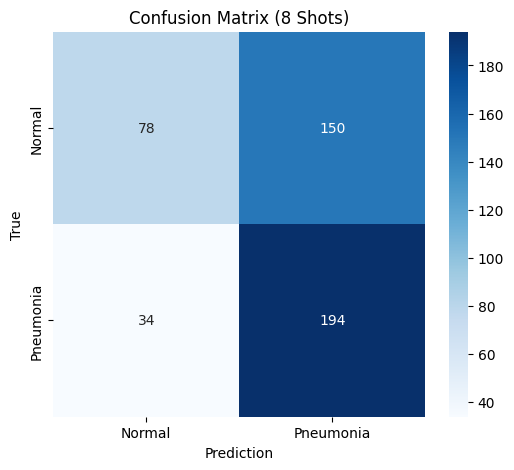

In [ ]:
N_SHOTS = 8
icl_examples = get_few_shot_examples(train_ds, total_shots=N_SHOTS)
y_true, y_pred = [], []

for sample in tqdm(test_ds):
    y_true.append(LABEL_MAP[sample["label"]])
    content, images = [], []
    for i, ex in enumerate(icl_examples):
        content.append({"type": "text", "text": f"--- EXAMPLE {i+1} ---\nDiagnosis: {ex['label']}\nImage:"})
        content.append({"type": "image"})
        images.append(ex["image"])
    content.append({"type": "text", "text": "\n--- TASK ---\nYou are an expert radiologist. Analyze this chest X-ray and classify it as 'Normal' or 'Pneumonia'. Output ONLY the single word answer.\nFinal Image:"})
    content.append({"type": "image"})
    images.append(sample["image"])
    messages = [{"role": "user", "content": content}]
    input_text = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=input_text, images=images, return_tensors="pt", padding=True).to("cuda")
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=15, temperature=0.01, use_cache=True)
    response = processor.batch_decode(output[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()
    pred_label = "Pneumonia" if "Pneumonia" in response else "Normal" if "Normal" in response else "Error"
    y_pred.append(pred_label)

acc = accuracy_score(y_true, y_pred) * 100
print(f"Accuracy for {N_SHOTS}-shot: {acc:.2f}%")

acc = accuracy_score(y_true, y_pred) * 100
print(f"Accuracy for {N_SHOTS}-shot: {acc:.2f}%")
record_and_save_run(
    y_true,
    y_pred,
    setup=f"{N_SHOTS}shot",
    model="gemma-3-4b-it",
    accuracy_pct=acc,
)


# **10 shots**

100%|██████████| 456/456 [1:10:17<00:00,  9.25s/it]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ 10-Shot Metrics
              precision    recall  f1-score   support

      Normal       0.71      0.46      0.55       228
   Pneumonia       0.60      0.81      0.69       228

    accuracy                           0.63       456
   macro avg       0.65      0.63      0.62       456
weighted avg       0.65      0.63      0.62       456



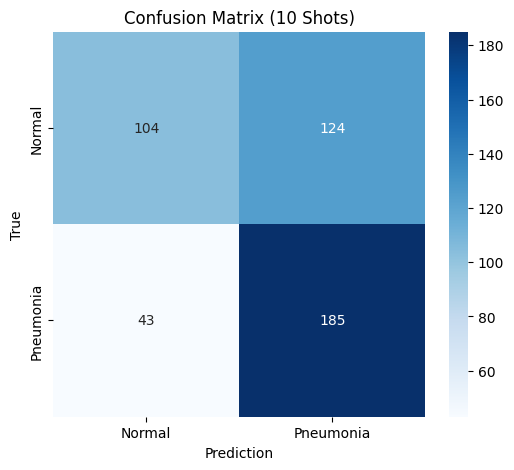

In [ ]:
N_SHOTS = 10
icl_examples = get_few_shot_examples(train_ds, total_shots=N_SHOTS)
y_true, y_pred = [], []

for sample in tqdm(test_ds):
    y_true.append(LABEL_MAP[sample["label"]])
    content, images = [], []
    for i, ex in enumerate(icl_examples):
        content.append({"type": "text", "text": f"--- EXAMPLE {i+1} ---\nDiagnosis: {ex['label']}\nImage:"})
        content.append({"type": "image"})
        images.append(ex["image"])
    content.append({"type": "text", "text": "\n--- TASK ---\nYou are an expert radiologist. Analyze this chest X-ray and classify it as 'Normal' or 'Pneumonia'. Output ONLY the single word answer.\nFinal Image:"})
    content.append({"type": "image"})
    images.append(sample["image"])
    messages = [{"role": "user", "content": content}]
    input_text = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=input_text, images=images, return_tensors="pt", padding=True).to("cuda")
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=15, temperature=0.01, use_cache=True)
    response = processor.batch_decode(output[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()
    pred_label = "Pneumonia" if "Pneumonia" in response else "Normal" if "Normal" in response else "Error"
    y_pred.append(pred_label)

acc = accuracy_score(y_true, y_pred) * 100
print(f"Accuracy for {N_SHOTS}-shot: {acc:.2f}%")

acc = accuracy_score(y_true, y_pred) * 100
print(f"Accuracy for {N_SHOTS}-shot: {acc:.2f}%")
record_and_save_run(
    y_true,
    y_pred,
    setup=f"{N_SHOTS}shot",
    model="gemma-3-4b-it",
    accuracy_pct=acc,
)
